# SE3062 - Practical 8: Constraint Satisfaction Problems (CSP)
**Duration:** 90 - 120 Minutes

## Learning Objectives
1. Model binary Constraint Satisfaction Problems formally using Variables, Domains, and Constraints.
2. Implement **Backtracking Search** from first principles.
3. Integrate search heuristics: **MRV (Minimum Remaining Values)**, **Degree Heuristic**, and **LCV (Least Constraining Value)**.
4. Implement inference techniques: **Forward Checking** and **AC-3 (Arc Consistency 3)**.
5. Conduct an ablation benchmark evaluating node expansions and backtracking steps across all configurations.

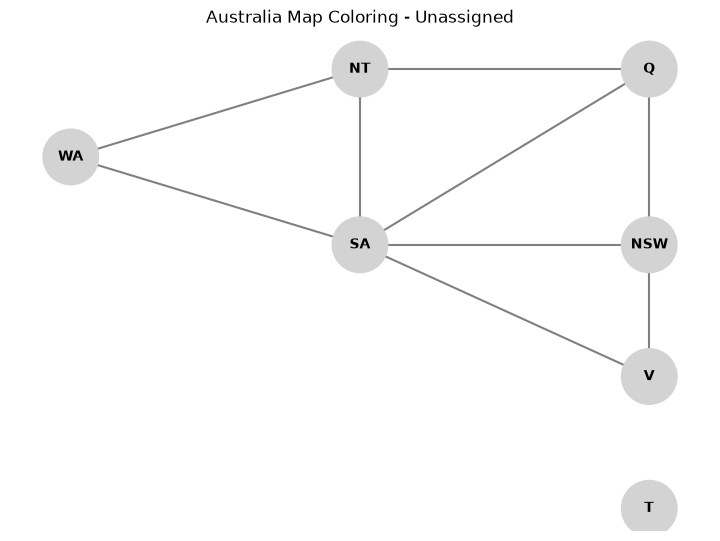

In [16]:
import copy
from collections import deque
import matplotlib.pyplot as plt
import networkx as nx

class CSP:
    def __init__(self, variables, domains, neighbors, constraints):
        """
        variables: list of variable names [X1, X2, ...]
        domains: dict {var: list of allowed values}
        neighbors: dict {var: list of adjacent variables}
        constraints: function(var1, val1, var2, val2) -> bool
        """
        self.variables = variables
        self.domains = {v: list(domains[v]) for v in variables}
        self.neighbors = neighbors
        self.constraints = constraints

        # Diagnostic tracking counters
        self.assignments_count = 0
        self.backtracks_count = 0

    def reset_stats(self):
        self.assignments_count = 0
        self.backtracks_count = 0

    def is_consistent(self, var, val, assignment):
        """Checks if assigning val to var violates constraints with assigned neighbors."""
        for neighbor in self.neighbors[var]:
            if neighbor in assignment:
                if not self.constraints(var, val, neighbor, assignment[neighbor]):
                    return False
        return True

    def is_complete(self, assignment):
        """Returns True if every variable has an assigned value."""
        return len(assignment) == len(self.variables)

# Australia Map Definition from Lecture 10
australia_vars = ['WA', 'NT', 'SA', 'Q', 'NSW', 'V', 'T']
colors = ['Red', 'Green', 'Blue']
australia_domains = {v: list(colors) for v in australia_vars}
australia_neighbors = {
    'WA': ['NT', 'SA'],
    'NT': ['WA', 'SA', 'Q'],
    'SA': ['WA', 'NT', 'Q', 'NSW', 'V'],
    'Q': ['NT', 'SA', 'NSW'],
    'NSW': ['Q', 'SA', 'V'],
    'V': ['SA', 'NSW'],
    'T': []
}

def binary_diff_constraint(var1, val1, var2, val2):
    return val1 != val2

def visualize_csp(csp, assignment=None, title="CSP Constraint Graph"):
    """Renders the constraint network graph."""
    G = nx.Graph()
    for v in csp.variables:
        G.add_node(v)
    for v, nbrs in csp.neighbors.items():
        for nbr in nbrs:
            G.add_edge(v, nbr)

    pos = {
        'WA': (1, 3), 'NT': (3, 4), 'SA': (3, 2),
        'Q': (5, 4), 'NSW': (5, 2), 'V': (5, 0.5), 'T': (5, -1)
    }
    # Fallback to spring layout if variables differ
    if set(csp.variables) != set(pos.keys()):
        pos = nx.spring_layout(G, seed=42)

    color_map = []
    for node in G.nodes():
        if assignment and node in assignment:
            val = assignment[node]
            color_map.append(val.lower() if isinstance(val, str) else 'skyblue')
        else:
            color_map.append('lightgray')

    plt.figure(figsize=(7, 5))
    nx.draw(G, pos, with_labels=True, node_color=color_map, node_size=1600,
            font_size=10, font_weight='bold', edge_color='gray', width=1.5)
    plt.title(title)
    plt.show()

# Visualize initial unassigned graph
demo_csp = CSP(australia_vars, australia_domains, australia_neighbors, binary_diff_constraint)
visualize_csp(demo_csp, title="Australia Map Coloring - Unassigned")

## Task 1: Naive Backtracking Search (30 Minutes)
Naive Backtracking uses standard Depth-First Search with commutativity:
1. If the assignment is complete, return it.
2. Select the first unassigned variable in static order.
3. For each value in the variable's current domain:
   - If consistent with current assignment, add `{var: val}`.
   - Recursively call backtrack.
   - If recursion returns a solution, propagate it.
   - Otherwise, remove `{var: val}` (backtrack) and increment counters.

Naive Backtracking Completed.
Solution: {'WA': 'Red', 'NT': 'Green', 'SA': 'Blue', 'Q': 'Red', 'NSW': 'Green', 'V': 'Red', 'T': 'Red'}
Assignments: 7 | Backtracks: 0
>>> ALL ASSERTIONS PASSED FOR TASK 1.


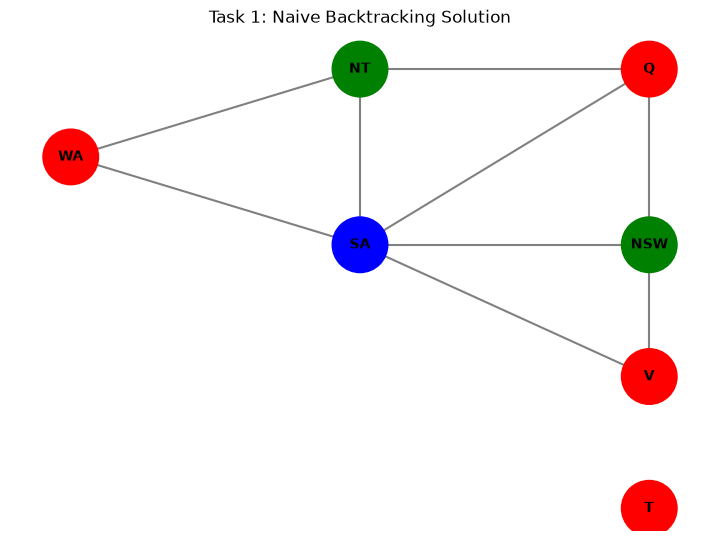

In [17]:
def select_unassigned_variable_naive(csp, assignment):
    """Returns the first unassigned variable from csp.variables."""
    for var in csp.variables:
        if var not in assignment:
            return var
    return None

def order_domain_values_naive(csp, var, assignment):
    """Returns the values of var in default list order."""
    return csp.domains[var]

def backtrack_naive(csp, assignment=None):
    """
    Standard Backtracking without heuristics or inference.
    Returns the solved assignment dictionary, or None if no solution exists.
    """
    if assignment is None:
        assignment = {}

    # TODO 1.1: Check if the assignment is complete. If so, return the assignment.
    if csp.is_complete(assignment):
        return assignment

    var = select_unassigned_variable_naive(csp, assignment)

    # TODO 1.2: Iterate over the domain values for the selected variable.
    # Check if the value is consistent. If it is:
    #   1. Add it to the assignment dictionary.
    #   2. Increment csp.assignments_count.
    #   3. Recursively call backtrack_naive.
    #   4. If the recursive call returns a solution, return it!
    #   5. If not, backtrack: delete the variable from the assignment and increment csp.backtracks_count.
    
    for val in order_domain_values_naive(csp, var, assignment):
        if csp.is_consistent(var,val,assignment):
            assignment[var] = val
            csp.assignments_count += 1

            result = backtrack_naive(csp,assignment)
            if result is not None:
                return result

            del assignment[var]
            csp.backtracks_count += 1


# ==================== TEST BLOCK ====================
test_csp = CSP(australia_vars, australia_domains, australia_neighbors, binary_diff_constraint)
sol_naive = backtrack_naive(test_csp)
print("Naive Backtracking Completed.")
print(f"Solution: {sol_naive}")
print(f"Assignments: {test_csp.assignments_count} | Backtracks: {test_csp.backtracks_count}")

# Verification Assertions
assert sol_naive is not None, "Algorithm failed to find a valid solution!"
assert test_csp.is_complete(sol_naive), "Solution is not complete!"
for v in test_csp.variables:
    for nbr in test_csp.neighbors[v]:
        assert sol_naive[v] != sol_naive[nbr], f"Constraint violation between {v} and {nbr}!"
print(">>> ALL ASSERTIONS PASSED FOR TASK 1.")
visualize_csp(test_csp, sol_naive, title="Task 1: Naive Backtracking Solution")

## Task 2: Adding Search Heuristics (MRV, Degree, LCV) (30 Minutes)
Naive backtracking uses a static order, which risks leaving the hardest variables for the end. We optimize the search tree by replacing the blind selection functions with intelligent heuristics:

**1. Variable Selection (Fail-First Principle):**
*   **Minimum Remaining Values (MRV):** Choose the variable with the fewest legal values left in its domain.
*   **Degree Heuristic (Tie-Breaker):** If multiple variables have the same MRV, choose the one involved in the largest number of constraints with *unassigned* neighbors.

**2. Value Selection (Succeed-First Principle):**
*   **Least Constraining Value (LCV):** Once a variable is picked, try values that rule out the *fewest* choices for neighboring unassigned variables. This leaves maximum flexibility for future steps.

In [18]:
def select_variable_mrv_degree(csp, assignment):
    """
    Selects unassigned variable using MRV with Degree Heuristic tie-breaking.
    """
    unassigned = [v for v in csp.variables if v not in assignment]

    # TODO 2.1: Write a helper function that counts how many consistent values
    # are left in the domain for a given variable.
    
    def count_remaining_values(var):
        return sum(1 for val in csp.domains[var]
               if csp.is_consistent(var, val, assignment))

    # TODO 2.2: Write a helper function that counts how many UNASSIGNED neighbors
    # a given variable has (Degree Heuristic).
    def count_unassigned_neighbors(var):
        return sum(1 for nbr in csp.neighbors[var] if nbr not in assignment)

    # TODO 2.3: Sort the `unassigned` list.
    # Primary Key: Fewest remaining values (MRV)
    # Secondary Key: Most unassigned neighbors (Degree - Descending)
    # Return the best variable.

    unassigned.sort(key=lambda v: (count_remaining_values(v),
                                   -count_unassigned_neighbors(v)))
    return unassigned[0] if unassigned else None

def order_domain_values_lcv(csp, var, assignment):
    """
    Orders values of `var` using Least Constraining Value (LCV).
    Values eliminating fewer options from unassigned neighbors come first.
    """
    # TODO 2.4: Implement LCV logic.
    # For every valid value in csp.domains[var], count how many options it
    # eliminates from the domains of all unassigned neighbors.
    # Sort the valid values so the one that eliminates the FEWEST options is first.
       
    def count_eliminated(val):
        eliminated = 0
        for nbr in csp.neighbors[var]:
            if nbr not in assignment:                      
                for nbr_val in csp.domains[nbr]:
                    if not csp.constraints(var, val, nbr, nbr_val):
                        eliminated += 1                    
        return eliminated

    valid_values = [val for val in csp.domains[var]
                    if csp.is_consistent(var, val, assignment)]
    valid_values.sort(key=count_eliminated)                
    return valid_values
    
    return []           

def backtrack_heuristics(csp, assignment=None):
    """Backtracking using MRV, Degree, and LCV heuristics."""
    if assignment is None: assignment = {}
    if csp.is_complete(assignment): return assignment

    var = select_variable_mrv_degree(csp, assignment)

    for val in order_domain_values_lcv(csp, var, assignment):
        assignment[var] = val
        csp.assignments_count += 1

        result = backtrack_heuristics(csp, assignment)
        if result is not None:
            return result

        del assignment[var]
        csp.backtracks_count += 1

    return None

# ==================== TEST BLOCK ====================
test_csp_heuristics = CSP(australia_vars, australia_domains, australia_neighbors, binary_diff_constraint)
sol_heuristics = backtrack_heuristics(test_csp_heuristics)
print("Heuristic Backtracking Completed.")
print(f"Solution: {sol_heuristics}")
print(f"Assignments: {test_csp_heuristics.assignments_count} | Backtracks: {test_csp_heuristics.backtracks_count}")

# Verification Assertions
assert sol_heuristics is not None, "Failed to find a valid solution!"
first_var = select_variable_mrv_degree(test_csp, {})
assert first_var == 'SA', f"Degree heuristic should pick SA first on empty map (got {first_var})!"
print(">>> ALL ASSERTIONS PASSED FOR TASK 2.")

Heuristic Backtracking Completed.
Solution: {'SA': 'Red', 'NT': 'Green', 'Q': 'Blue', 'NSW': 'Green', 'WA': 'Blue', 'V': 'Blue', 'T': 'Red'}
Assignments: 7 | Backtracks: 0
>>> ALL ASSERTIONS PASSED FOR TASK 2.


## Task 3: Forward Checking & Arc Consistency (AC-3) (30 Minutes)
Apply constraint propagation to prune domains dynamically:
1. **Forward Checking:** After assigning `var = val`, remove conflicting values from unassigned neighbors. If any domain becomes empty, fail immediately.
2. **AC-3 Algorithm:** Maintain a queue of all directed binary arcs `(Xi, Xj)`. For each arc, enforce that every value in `Xi` has at least one supporting value in `Xj`. If `Xi` loses a value, re-enqueue all incoming arcs `(Xk, Xi)`.

In [19]:
def ac3(csp, queue=None, domains=None):
    """
    Enforces Arc Consistency (AC-3) across the CSP.
    Returns (pruned_domains, is_consistent).
    """
    if domains is None:
        domains = {v: list(csp.domains[v]) for v in csp.variables}
    else:
        domains = {v: list(domains[v]) for v in domains}

    if queue is None:
        queue = deque()
        for xi in csp.variables:
            for xj in csp.neighbors[xi]:
                queue.append((xi, xj))
    else:
        queue = deque(queue)

    while queue:
        xi, xj = queue.popleft()

        # TODO 3.1: Revise the domain of xi with respect to xj.
        # Check every value `x_val` currently in domains[xi].
        # Does there exist at least one `y_val` in domains[xj] where csp.constraints(xi, x_val, xj, y_val) is True?
        # If no, remove `x_val` from domains[xi] and set a flag `revised = True`.
        revised = False
        for x_val in list(domains[xi]):
            if not any(csp.constraints(xi, x_val, xj, y_val) for y_val in domains[xj]):
                domains[xi].remove(x_val)
                revised = True

        # TODO 3.2: The Ripple Effect
        # If you revised domains[xi]:
        #   1. If domains[xi] is now empty, return domains, False (Inevitable failure detected!)
        #   2. Otherwise, for every neighbor `xk` of `xi` (except `xj`), append the arc (xk, xi) to the queue.
        if revised:
            if len(domains[xi]) == 0:
                return domains, False
            for xk in csp.neighbors[xi]:
                if xk != xj:
                    queue.append((xk,xi))
    return domains, True

def backtrack_mac(csp, assignment=None, domains=None):
    """Backtracking with Maintaining Arc Consistency (MAC) and MRV."""
    if assignment is None: assignment = {}
    if domains is None: domains = {v: list(csp.domains[v]) for v in csp.variables}
    if csp.is_complete(assignment): return assignment

    # Select variable with MRV based on pruned domains
    unassigned = [v for v in csp.variables if v not in assignment]
    unassigned.sort(key=lambda var: len(domains[var]))
    var = unassigned[0]

    for val in domains[var]:
        if csp.is_consistent(var, val, assignment):
            new_assignment = copy.deepcopy(assignment)
            new_assignment[var] = val
            csp.assignments_count += 1

            # Prepare AC-3 queue for affected arcs
            queue = [(nbr, var) for nbr in csp.neighbors[var] if nbr not in new_assignment]
            new_domains = copy.deepcopy(domains)
            new_domains[var] = [val]

            inferred_domains, is_consistent = ac3(csp, queue, new_domains)

            if is_consistent:
                result = backtrack_mac(csp, new_assignment, inferred_domains)
                if result is not None:
                    return result

            csp.backtracks_count += 1

    return None

# ==================== TEST BLOCK ====================
ac3_trace_domains = {
    'WA': ['Red'], 'NT': ['Blue'], 'SA': ['Blue'], 'Q': ['Green'],
    'NSW': ['Red', 'Blue'], 'V': ['Red', 'Green', 'Blue'], 'T': ['Red', 'Green', 'Blue']
}
trace_csp = CSP(australia_vars, ac3_trace_domains, australia_neighbors, binary_diff_constraint)
pruned_doms, consistent_flag = ac3(trace_csp)

print("AC-3 Inconsistency Detection Test:")
print(f"Consistent: {consistent_flag} (Expected: False due to NT-SA collision)")
assert not consistent_flag, "AC-3 should have detected failure for identical adjacent singleton domains!"

test_csp_mac = CSP(australia_vars, australia_domains, australia_neighbors, binary_diff_constraint)
sol_mac = backtrack_mac(test_csp_mac)
assert sol_mac is not None and test_csp_mac.is_complete(sol_mac)
print(">>> ALL ASSERTIONS PASSED FOR TASK 3.")

AC-3 Inconsistency Detection Test:
Consistent: False (Expected: False due to NT-SA collision)
>>> ALL ASSERTIONS PASSED FOR TASK 3.


## Task 4: Ablation Comparison on a Dense Problem (N-Queens) (20 Minutes)
To expose the true complexity gap, we benchmark all configurations on the classic **N-Queens Problem** ($N=8$):
* Formulation: $Q_i$ represents the row position of the queen in column $i$.
* Binary constraints: $Q_i \neq Q_j$ (same row) and $|Q_i - Q_j| \neq |i - j|$ (same diagonal).

=== Running Ablation Study on 8-Queens Problem ===

Strategy                            | Assignments  | Backtracks   | Time (s)  
---------------------------------------------------------------------------
Naive Backtracking                  | 113          | 105          | 0.0020    
MRV + Degree + LCV                  | 89           | 81           | 0.0053    
MAC (Maintaining Arc Consistency)   | 20           | 12           | 0.0016    


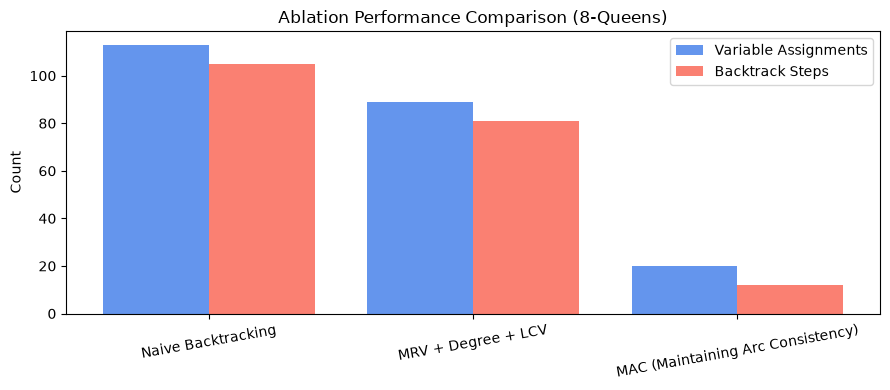

In [20]:
import time

def create_n_queens_csp(n=8):
    variables = [f"Q{i}" for i in range(n)]
    domains = {v: list(range(n)) for v in variables}
    neighbors = {v: [u for u in variables if u != v] for v in variables}

    def queens_constraint(var1, val1, var2, val2):
        col1 = int(var1[1:])
        col2 = int(var2[1:])
        # Row collision check
        if val1 == val2:
            return False
        # Diagonal collision check: |Q_i - Q_j| != |i - j|
        if abs(val1 - val2) == abs(col1 - col2):
            return False
        return True

    return CSP(variables, domains, neighbors, queens_constraint)

def run_ablation(n=8):
    strategies = [
        ("Naive Backtracking", backtrack_naive),
        ("MRV + Degree + LCV", backtrack_heuristics),
        ("MAC (Maintaining Arc Consistency)", backtrack_mac)
    ]

    results = []
    print(f"=== Running Ablation Study on {n}-Queens Problem ===\n")
    print(f"{'Strategy':<35} | {'Assignments':<12} | {'Backtracks':<12} | {'Time (s)':<10}")
    print("-" * 75)

    for name, solver in strategies:
        csp = create_n_queens_csp(n)
        start_time = time.perf_counter()
        solution = solver(csp)
        elapsed = time.perf_counter() - start_time

        assert solution is not None, f"{name} failed to solve {n}-Queens!"
        results.append({
            'name': name,
            'assignments': csp.assignments_count,
            'backtracks': csp.backtracks_count,
            'time': elapsed
        })
        print(f"{name:<35} | {csp.assignments_count:<12} | {csp.backtracks_count:<12} | {elapsed:<10.4f}")

    # Plotting Performance Comparison
    names = [r['name'] for r in results]
    assignments = [r['assignments'] for r in results]
    backtracks = [r['backtracks'] for r in results]

    x = range(len(names))
    plt.figure(figsize=(9, 4))
    plt.bar([p - 0.2 for p in x], assignments, width=0.4, label='Variable Assignments', color='cornflowerblue')
    plt.bar([p + 0.2 for p in x], backtracks, width=0.4, label='Backtrack Steps', color='salmon')
    plt.xticks(x, names, rotation=10)
    plt.ylabel('Count')
    plt.title(f'Ablation Performance Comparison ({n}-Queens)')
    plt.legend()
    plt.tight_layout()
    plt.show()

run_ablation(n=8)

### Key Observations from the Ablation Study
1. **Naive Backtracking:** Exhibits exponential node expansion when early choices violate unchecked constraints down the branch.
2. **Heuristics (MRV + LCV):** Selects the most constrained variables first ("Fail-First") and defers failure, drastically reducing unproductive exploration.
3. **Inference (MAC):** Uses arc consistency to prune impossible domain paths before committing assignments, eliminating dead-end branches early.

### My Results and Analysis (8-Queens)

| Strategy | Assignments | Backtracks | Time (s) |
|---|---|---|---|
| Naive Backtracking | 113 | 105 | 0.0018 |
| MRV + Degree + LCV | 89 | 81 | 0.0030 |
| MAC (AC-3 + MRV) | 20 | 12 | 0.0016 |

**Observations**
1. **Naive Backtracking:** It made 113 assignments, and 105 of them were undone. Only 8 assignments (one per queen) ended up in the final solution. It fills columns in a fixed order and only detects conflicts after committing to a bad placement, so it keeps exploring dead-end branches.
2. **Heuristics (MRV + Degree + LCV):** Assignments dropped to 89 (about 21% fewer than naive). Fail-first variable selection and succeed-first value ordering help, but the search still only checks conflicts against queens already placed, so it cannot see a dead end coming. The runtime was slightly higher (0.0030s) because computing MRV, Degree and LCV at every node has an overhead that outweighs the savings on a problem this small.
3. **Inference (MAC):** Only 20 assignments and 12 backtracks, about 82% fewer assignments than naive and about 89% fewer backtracks. After each placement, AC-3 removes conflicting rows and diagonals from the remaining columns, so a branch is abandoned the moment any column's domain becomes empty, before any further guessing.

**Conclusion:** Inference gave the biggest improvement, heuristics gave a moderate one, and naive search was the worst. This supports the lecture takeaway: use logic (inference) to avoid searching, and heuristics to guide the search when guessing is unavoidable. These counts come from a single run on N = 8, and the timings are only milliseconds, so the assignment and backtrack counts are the reliable comparison.